# Data profiling

What is in the dataset, before any network or text analysis. Run `data_import.ipynb` first: this notebook only reads its outputs and saves nothing.

**The two units:**

| unit | file | one row per |
|---|---|---|
| device | `data/processed/pma_devices_2020_2025.csv` | PMA number (one approved high-risk device), active in 2020-2025 |
| report | `data/processed/maude_reports.csv(.gz)` | adverse event report received in 2020-2025 that names a PMA number |

**Scope used from here on:** only devices that have at least one report, and only reports that link to one of those devices. A report links to a device through its PMA number, so each report is one report-device pair.

Sections:
1. How many devices, reports and links
2. Reports per device
3. Patients: sex and age
4. Devices: medical field, manufacturer, age
5. Severity (the closest thing to a risk level)
6. Summary

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED_DIR = Path("data/processed")

# Older approvals still in use count too, so the first decision year goes back decades.
COMMITTEES = {
    "AN": "Anesthesiology", "CH": "Clinical chemistry", "CV": "Cardiovascular", "DE": "Dental",
    "EN": "Ear, nose, throat", "GU": "Gastro and urology", "HE": "Hematology", "HO": "General hospital",
    "IM": "Immunology", "MG": "Medical genetics", "MI": "Microbiology", "NE": "Neurology",
    "OB": "Obstetrics and gynecology", "OP": "Ophthalmic", "OR": "Orthopedic", "PA": "Pathology",
    "PM": "Physical medicine", "RA": "Radiology", "SU": "General and plastic surgery", "TX": "Clinical toxicology",
}
SEVERITY_ORDER = ["Death", "Injury", "Malfunction"]
SEVERITY_COLORS = {"Death": "#b2182b", "Injury": "#ef8a62", "Malfunction": "#9db4c8"}
BLUE = "#3b6ea5"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def with_n(labels, ns):
    """Add the count to each category label, e.g. 'Neurology (n=146,495)'."""
    return [f"{label} (n={n:,})" for label, n in zip(labels, ns)]

## 1. How many devices, reports and links

The reports file is large, so only the columns needed here are read, and text is left out. The uncompressed `.csv` is used if it exists, because it loads faster.

In [21]:
devices_all = pd.read_csv(PROCESSED_DIR / "pma_devices_2020_2025.csv", parse_dates=["first_decision", "latest_decision"])

report_path = PROCESSED_DIR / "maude_reports.csv"
if not report_path.exists():
    report_path = PROCESSED_DIR / "maude_reports.csv.gz"

reports_all = pd.read_csv(
    report_path,
    usecols=["mdr_report_key", "pma_number", "event_type", "patient_age", "patient_sex",
             "patient_outcomes", "n_devices", "report_source", "year_received"],
    dtype={"mdr_report_key": str, "pma_number": "category", "event_type": "category",
           "patient_sex": "category", "report_source": "category", "patient_age": str, "patient_outcomes": str},
)
reports_all.shape, devices_all.shape

((2422364, 9), (920, 22))

In [22]:
has_report = devices_all["n_reports"] > 0
devices = devices_all[has_report].copy()
devices["committee"] = devices["advisory_committee"].map(COMMITTEES).fillna(devices["advisory_committee"])

linked = reports_all["pma_number"].isin(devices["pma_number"])
reports = reports_all[linked].copy()
reports["committee"] = reports["pma_number"].map(devices.set_index("pma_number")["committee"]).astype("category")

overview = {
    "devices active in 2020-2025": len(devices_all),
    "  with at least one report (used)": has_report.sum(),
    "  with no report (dropped)": (~has_report).sum(),
    "reports in 2020-2025 naming a PMA number": len(reports_all),
    "  linked to a device (used)": linked.sum(),
    "  not linked (dropped)": (~linked).sum(),
    "reports naming more than one device": (reports["n_devices"] > 1).sum(),
    "product codes among used devices": devices["product_code"].nunique(),
    "manufacturer names among used devices": devices["latest_applicant"].nunique(),
}
pd.Series(overview, name="count").to_frame()

,count
devices active in 2020-2025,920
with at least one report (used),713
with no report (dropped),207
reports in 2020-2025 naming a PMA number,2422364
linked to a device (used),2422364
not linked (dropped),0
reports naming more than one device,4036
product codes among used devices,249
manufacturer names among used devices,332


Every report links to a device, because `data_import.ipynb` already dropped reports with mistyped PMA numbers. The loss is all on the device side: devices with an FDA decision in 2020-2025 but no report.

A report can list more than one physical device, but it carries only one PMA number, so it counts once, for that device.

In [23]:
assert reports["mdr_report_key"].is_unique, "a report appears twice"
assert devices["pma_number"].is_unique, "a device appears twice"
assert devices["n_reports"].sum() == len(reports), "report counts in the device table do not match the reports"
print("All checks passed")

All checks passed


## 2. Reports per device

This is the degree of each device in the report-device pairs. It is very uneven, so the plots use log scales.

In [24]:
counts = devices["n_reports"].sort_values(ascending=False)
shares = counts.cumsum() / counts.sum()

stats = {
    "minimum": counts.min(),
    "median": counts.median(),
    "mean": round(counts.mean()),
    "90th percentile": counts.quantile(0.9),
    "maximum": counts.max(),
    "devices with fewer than 10 reports": (counts < 10).sum(),
    "devices with at least 100 reports": (counts >= 100).sum(),
    "devices with at least 1,000 reports": (counts >= 1_000).sum(),
    "devices holding half of all reports": (shares < 0.5).sum() + 1,
    "share of reports from the top 10 devices": round(shares.iloc[9], 3),
}
pd.Series(stats, name="reports per device", dtype=object).to_frame()

,reports per device
minimum,1
median,75.0
mean,3397
90th percentile,6106.4
maximum,203612
devices with fewer than 10 reports,192
devices with at least 100 reports,334
"devices with at least 1,000 reports",152
devices holding half of all reports,16
share of reports from the top 10 devices,0.394


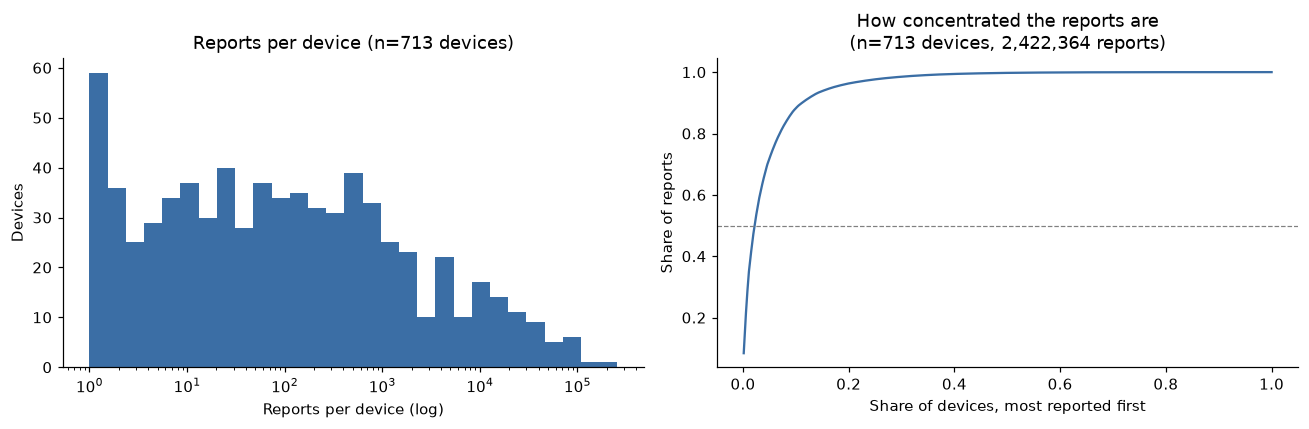

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

bins = np.logspace(0, np.log10(counts.max()) + 0.1, 30)
ax1.hist(counts, bins=bins, color=BLUE)
ax1.set(xscale="log", xlabel="Reports per device (log)", ylabel="Devices", title=f"Reports per device (n={len(counts):,} devices)")

ranks = np.arange(1, len(counts) + 1)
ax2.plot(ranks / len(counts), shares.values, color=BLUE)
ax2.axhline(0.5, color="grey", lw=0.8, ls="--")
ax2.set(xlabel="Share of devices, most reported first", ylabel="Share of reports", title=f"How concentrated the reports are\n(n={len(counts):,} devices, {counts.sum():,} reports)")
plt.tight_layout()

In [26]:
top = devices.nlargest(15, "n_reports")[["pma_number", "trade_name", "latest_applicant", "committee", "n_reports", "harm_share"]]
top["share_of_all_reports"] = (top["n_reports"] / counts.sum()).round(3)
top.round({"harm_share": 2})

,pma_number,trade_name,latest_applicant,committee,n_reports,harm_share,share_of_all_reports
411,P160017,MiniMed 670G System,"Medtronic Minimed, Inc.",Clinical chemistry,203612,0.15,0.084
422,P160030,Freestyle Libre Flash Glucose Monitoring System,"Abbott Diabetes Care, Inc.",Clinical chemistry,108707,0.11,0.045
810,P930039,"MEDTRONIC(R) CAPSUREFIX LEAD MODEL 4068,4067,4568","Medtronic, Inc.",Cardiovascular,106643,0.45,0.044
294,P120005,DEXCOM G4 PLATINUM CONTIUOUS GLUCOSE MONITORIN...,"Dexcom, Inc.",Clinical chemistry,101037,0.01,0.042
362,P150001,MINIMED 630G SYSTEM WITH SMARTGUARD(TM),Medtronic Minimed,Clinical chemistry,94713,0.18,0.039
79,P020056,NATRELLE SILICONE-FILLED BREAST IMPLANTS,Allergan,General and plastic surgery,82251,0.99,0.034
46,P010032,GENESIS AND EON FAMILY NEUROSTIMULATION (IPG) ...,ABBOTT MEDICAL,Neurology,77407,0.97,0.032
44,P010030,WEARABLE CARDIOVERTER DEFIBRILLATOR (WCD) 2000...,Zoll Manufacturing Corporation,Cardiovascular,73935,0.29,0.031
108,P030053,MEMORYGEL SILICONE GEL -FILLED BREAST IMPLANTS,Mentor Corp.,General and plastic surgery,54123,0.98,0.022
717,P840001,ITREL(R) TOTALLY IMPLANTABLE SPINAL CORD STIM....,Medtronic Neuromodulation,Neurology,52464,0.31,0.022


## 3. Patients: sex and age

Each report describes the first patient only. Missing values are kept as their own category, because how much is missing matters as much as the split.

Sex is Female or Male in 52.7% of reports
Among those, female: 53.0%


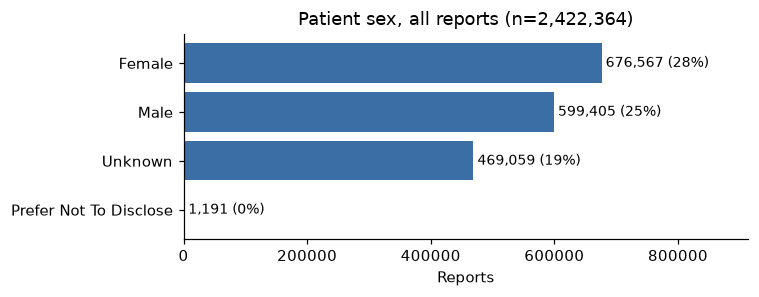

In [27]:
sex = reports["patient_sex"].astype(str).replace({"nan": "Not recorded"})
sex_counts = sex.value_counts()

known = sex[sex.isin(["Female", "Male"])]
print(f"Sex is Female or Male in {len(known) / len(sex):.1%} of reports")
print(f"Among those, female: {(known == 'Female').mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(sex_counts.index[::-1], sex_counts.values[::-1], color=BLUE)
ax.set(xlabel="Reports", title=f"Patient sex, all reports (n={len(sex):,})")
for y, v in enumerate(sex_counts.values[::-1]):
    ax.text(v, y, f" {v:,} ({v / len(sex):.0%})", va="center", fontsize=9)
ax.set_xlim(0, sex_counts.max() * 1.35)
plt.tight_layout()

Sex depends on the kind of device: some are only used in one sex. The share female is computed among reports where sex is known, and only for medical fields with at least 1,000 such reports.

,reports_with_sex,share_female,share_with_sex_known
committee,,,
Cardiovascular,542268,0.36,0.48
"Ear, nose, throat",21034,0.49,0.74
Orthopedic,12959,0.51,0.51
Clinical chemistry,293646,0.52,0.49
Gastro and urology,36104,0.53,0.61
General hospital,17931,0.55,0.63
Neurology,146495,0.59,0.66
Ophthalmic,27284,0.62,0.47
General and plastic surgery,168492,1.00,0.72


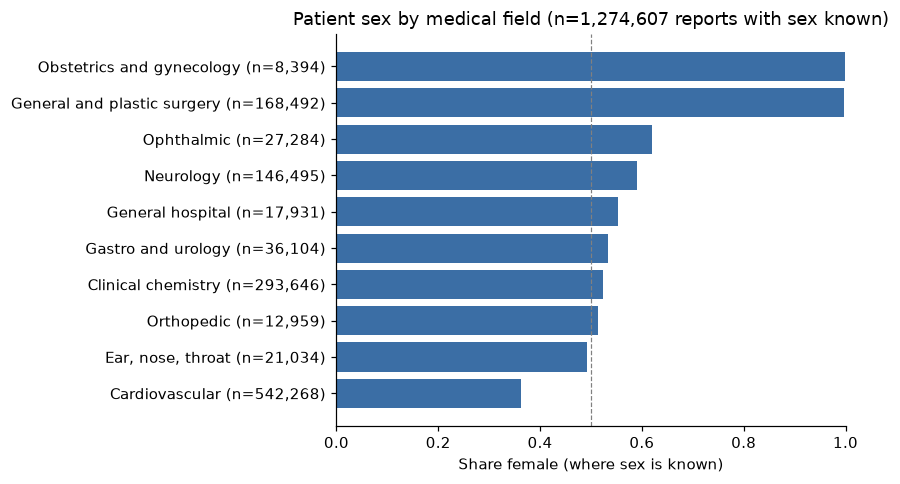

In [28]:
known_reports = reports[reports["patient_sex"].isin(["Female", "Male"])]
by_field = known_reports.groupby("committee", observed=True).agg(
    reports_with_sex=("patient_sex", "size"),
    share_female=("patient_sex", lambda s: (s == "Female").mean()),
)
coverage = reports.groupby("committee", observed=True)["patient_sex"].apply(lambda s: s.isin(["Female", "Male"]).mean())
by_field["share_with_sex_known"] = coverage
by_field = by_field[by_field["reports_with_sex"] >= 1_000].sort_values("share_female")

fig, ax = plt.subplots(figsize=(8, 0.35 * len(by_field) + 1))
ax.barh(with_n(by_field.index, by_field["reports_with_sex"]), by_field["share_female"], color=BLUE)
ax.axvline(0.5, color="grey", lw=0.8, ls="--")
ax.set(xlim=(0, 1), xlabel="Share female (where sex is known)",
       title=f"Patient sex by medical field (n={by_field['reports_with_sex'].sum():,} reports with sex known)")
plt.tight_layout()
by_field.round(2)

Ages are stored as text with a unit, such as `70 YR`, `3 MO` or `12 DA`. They are converted to years. Ages above 110 are treated as errors.

In [29]:
UNIT_YEARS = {"YR": 1, "MO": 1 / 12, "WK": 1 / 52, "DA": 1 / 365}

parts = reports["patient_age"].str.extract(r"^\s*(\d+(?:\.\d+)?)\s*([A-Z]+)\s*$")
age = pd.to_numeric(parts[0]) * parts[1].map(UNIT_YEARS)
implausible = age > 110
age = age.where(~implausible)
reports["age_years"] = age

age_summary = {
    "reports with a usable age": age.notna().sum(),
    "share with a usable age": round(age.notna().mean(), 3),
    "ages above 110, dropped": implausible.sum(),
    "patients under 18": (age < 18).sum(),
    "median age": age.median(),
    "interquartile range": f"{age.quantile(0.25):.0f}-{age.quantile(0.75):.0f}",
}
pd.Series(age_summary, name="value").to_frame()

,value
reports with a usable age,1571757
share with a usable age,0.649
"ages above 110, dropped",4340
patients under 18,53570
median age,62.0
interquartile range,46-73


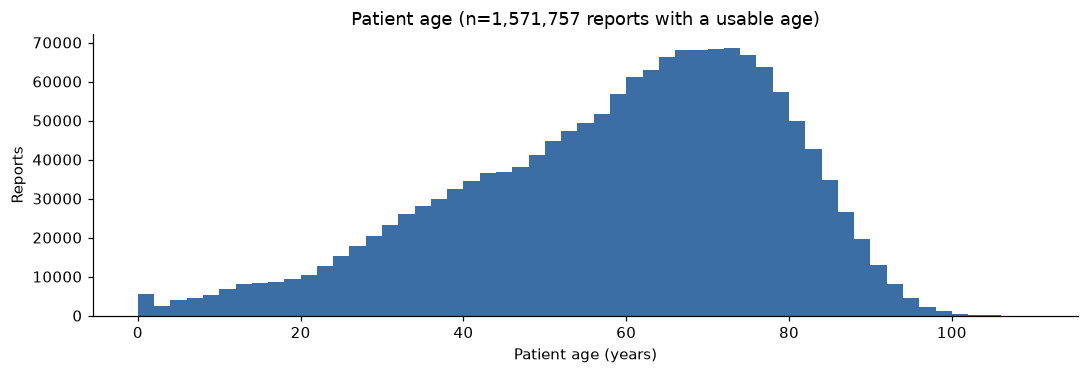

In [30]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(age.dropna(), bins=np.arange(0, 111, 2), color=BLUE)
ax.set(xlabel="Patient age (years)", ylabel="Reports", title=f"Patient age (n={age.notna().sum():,} reports with a usable age)")
plt.tight_layout()

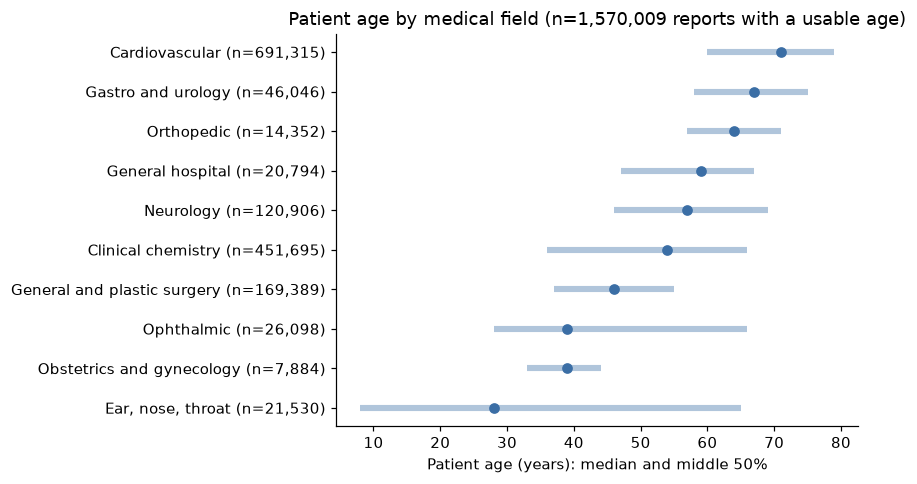

In [31]:
age_by_field = (
    reports.dropna(subset=["age_years"])
    .groupby("committee", observed=True)["age_years"]
    .agg(reports="size", median="median", q25=lambda a: a.quantile(0.25), q75=lambda a: a.quantile(0.75))
)
age_by_field = age_by_field[age_by_field["reports"] >= 1_000].sort_values("median")

fig, ax = plt.subplots(figsize=(8, 0.35 * len(age_by_field) + 1))
age_labels = with_n(age_by_field.index, age_by_field["reports"])
ax.hlines(age_labels, age_by_field["q25"], age_by_field["q75"], color=BLUE, lw=4, alpha=0.4)
ax.plot(age_by_field["median"], age_labels, "o", color=BLUE)
ax.set(xlabel="Patient age (years): median and middle 50%",
       title=f"Patient age by medical field (n={age_by_field['reports'].sum():,} reports with a usable age)")
plt.tight_layout()

## 4. Devices: medical field, manufacturer, age

The FDA assigns each device to an advisory committee, which is the closest thing to a device type. Fields are compared both by number of devices and by number of reports, because the two differ a lot.

,devices,reports,share_of_devices,share_of_reports
committee,,,,
Cardiovascular,326,1131807,0.457,0.467
Ophthalmic,72,57794,0.101,0.024
Orthopedic,66,25647,0.093,0.011
Gastro and urology,43,59476,0.060,0.025
General and plastic surgery,38,234904,0.053,0.097
Microbiology,38,1899,0.053,0.001
Neurology,30,223261,0.042,0.092
Pathology,21,384,0.029,0.000
"Ear, nose, throat",14,28463,0.020,0.012


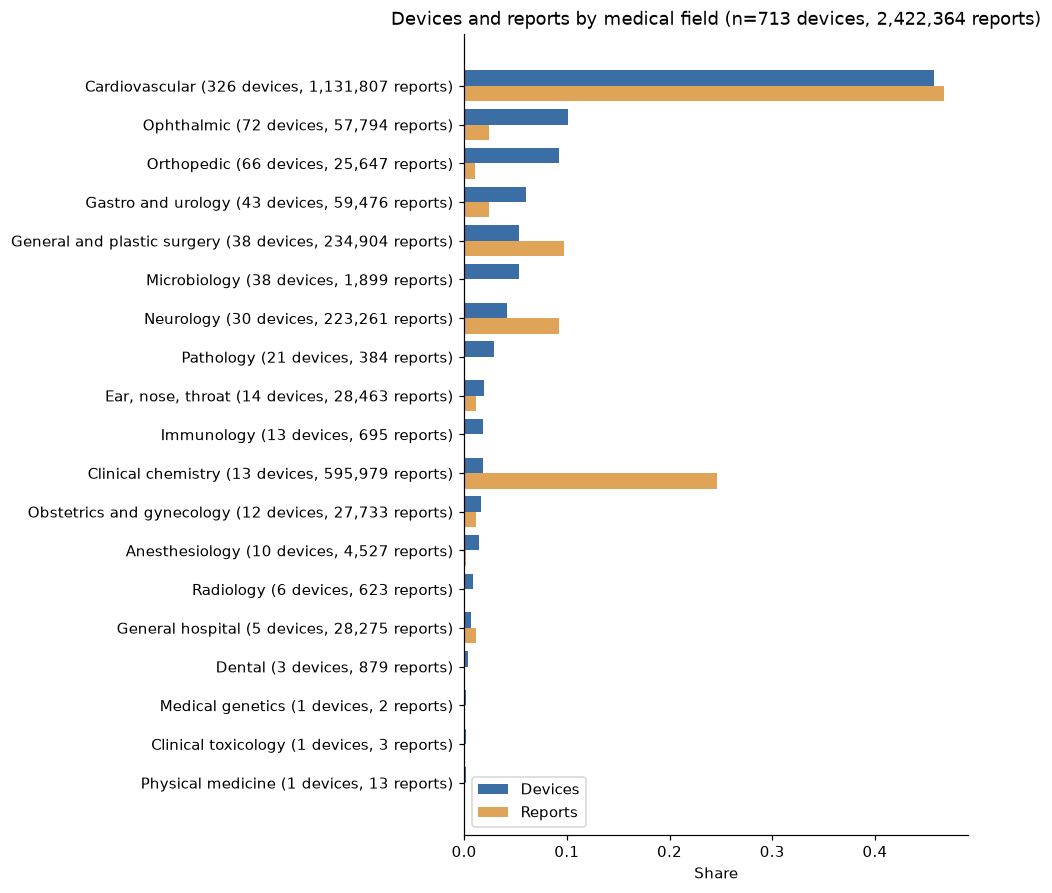

In [32]:
field = pd.DataFrame({
    "devices": devices["committee"].value_counts(),
    "reports": reports["committee"].value_counts(),
}).fillna(0).astype(int).sort_values("devices", ascending=False)
field["share_of_devices"] = field["devices"] / field["devices"].sum()
field["share_of_reports"] = field["reports"] / field["reports"].sum()

fig, ax = plt.subplots(figsize=(9, 0.38 * len(field) + 1))
y = np.arange(len(field))
ax.barh(y - 0.2, field["share_of_devices"], height=0.4, color=BLUE, label="Devices")
ax.barh(y + 0.2, field["share_of_reports"], height=0.4, color="#e0a458", label="Reports")
ax.set_yticks(y, [f"{name} ({d:,} devices, {r:,} reports)" for name, d, r in zip(field.index, field["devices"], field["reports"])])
ax.invert_yaxis()
ax.set(xlabel="Share", title=f"Devices and reports by medical field (n={field['devices'].sum():,} devices, {field['reports'].sum():,} reports)")
ax.legend()
plt.tight_layout()
field.round(3)

Manufacturer names are not resolved yet, so one company can appear under several names (see the caveats in `data_import.ipynb`). The counts below use the latest name on each device.

332 manufacturer names; the top 10 by reports hold 65% of reports


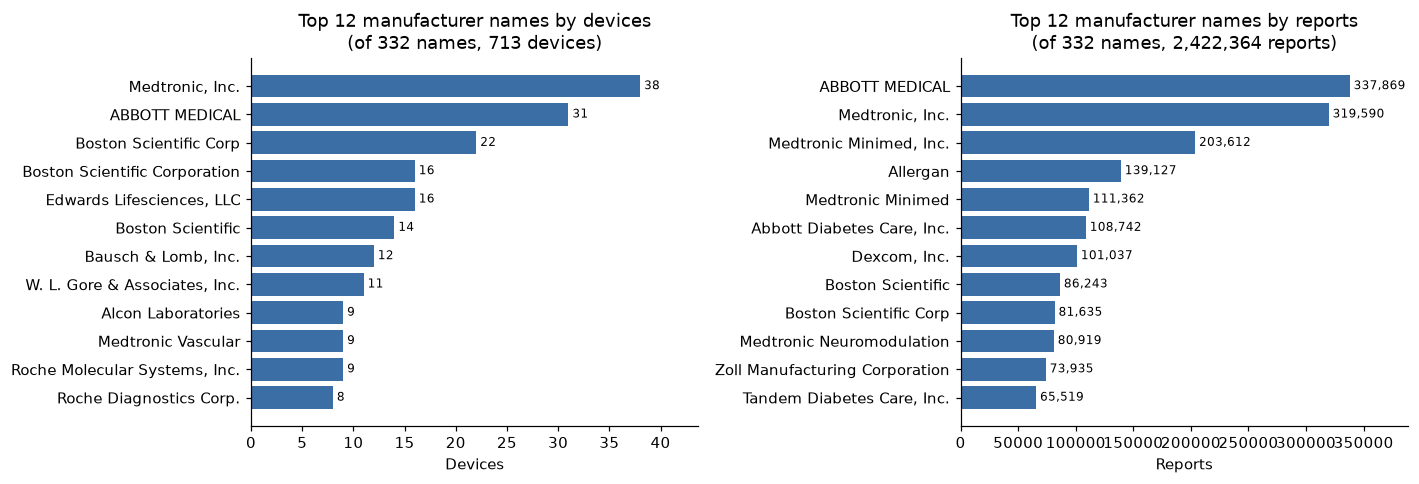

In [33]:
makers = devices.groupby("latest_applicant").agg(devices=("pma_number", "size"), reports=("n_reports", "sum"))
print(f"{len(makers)} manufacturer names; the top 10 by reports hold {makers['reports'].nlargest(10).sum() / makers['reports'].sum():.0%} of reports")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, column in [(ax1, "devices"), (ax2, "reports")]:
    top_makers = makers[column].nlargest(12)[::-1]
    ax.barh(top_makers.index, top_makers.values, color=BLUE)
    for y, v in enumerate(top_makers.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8)
    ax.set_xlim(0, top_makers.max() * 1.15)
    ax.set(xlabel=column.capitalize(),
           title=f"Top 12 manufacturer names by {column}\n(of {len(makers)} names, {makers[column].sum():,} {column})")
plt.tight_layout()

Devices approved before 2000: 25%. Median supplements per device: 33


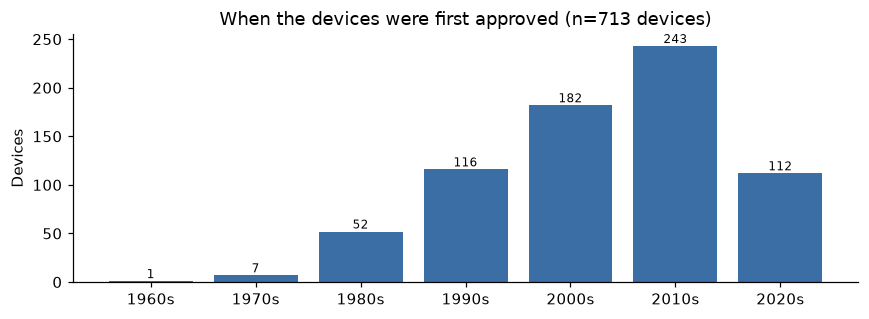

In [34]:
first_year = devices["first_decision"].dt.year
decade = (first_year // 10 * 10).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(decade.index.astype(str) + "s", decade.values, color=BLUE)
ax.bar_label(ax.containers[0], fontsize=8)
ax.set(ylabel="Devices", title=f"When the devices were first approved (n={decade.sum():,} devices)")
plt.tight_layout()
print(f"Devices approved before 2000: {(first_year < 2000).mean():.0%}. Median supplements per device: {devices['n_supplements'].median():.0f}")

## 5. Severity

**There is no risk class to compare.** Every PMA device is class III, the FDA's highest risk class, by definition. So risk has to come from the reports themselves:

- `event_type`: what the manufacturer reported, either a death, an injury, or a malfunction with no harm.
- `patient_outcomes`: more detail, such as hospitalization or required intervention. A report can have several.
- `harm_share` per device: the share of its reports that are a death or injury. It only means something with enough reports, so devices with fewer than 100 are left out of that plot.

event_type
Death          0.018
Injury         0.496
Malfunction    0.486

Reports with no outcome recorded: 47.9%


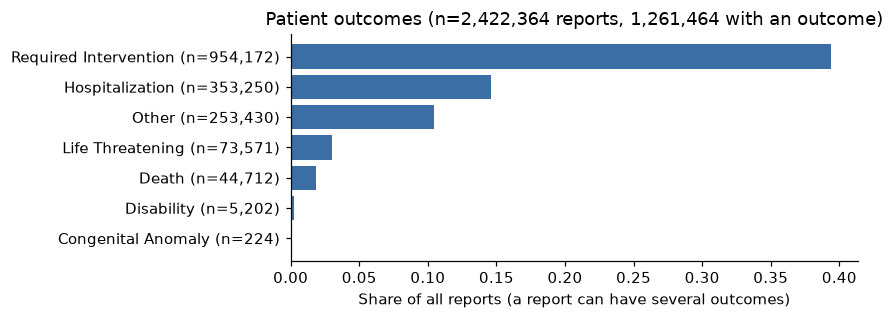

In [35]:
severity = reports["event_type"].value_counts().reindex(SEVERITY_ORDER)
print((severity / severity.sum()).round(3).to_string())

outcomes = reports["patient_outcomes"].dropna().str.split("; ").explode().value_counts()
print(f"\nReports with no outcome recorded: {reports['patient_outcomes'].isna().mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(with_n(outcomes.index[::-1], outcomes.values[::-1]), outcomes.values[::-1] / len(reports), color=BLUE)
ax.set(xlabel="Share of all reports (a report can have several outcomes)",
       title=f"Patient outcomes (n={len(reports):,} reports, {reports['patient_outcomes'].notna().sum():,} with an outcome)")
plt.tight_layout()

event_type,Death,Injury,Malfunction
committee,,,
Microbiology,0.001,0.022,0.977
Clinical chemistry,0.001,0.115,0.884
"Ear, nose, throat",0.000,0.489,0.511
Cardiovascular,0.036,0.516,0.447
Ophthalmic,0.000,0.596,0.404
General hospital,0.002,0.640,0.358
Gastro and urology,0.001,0.660,0.339
Neurology,0.008,0.713,0.279
Anesthesiology,0.036,0.750,0.214


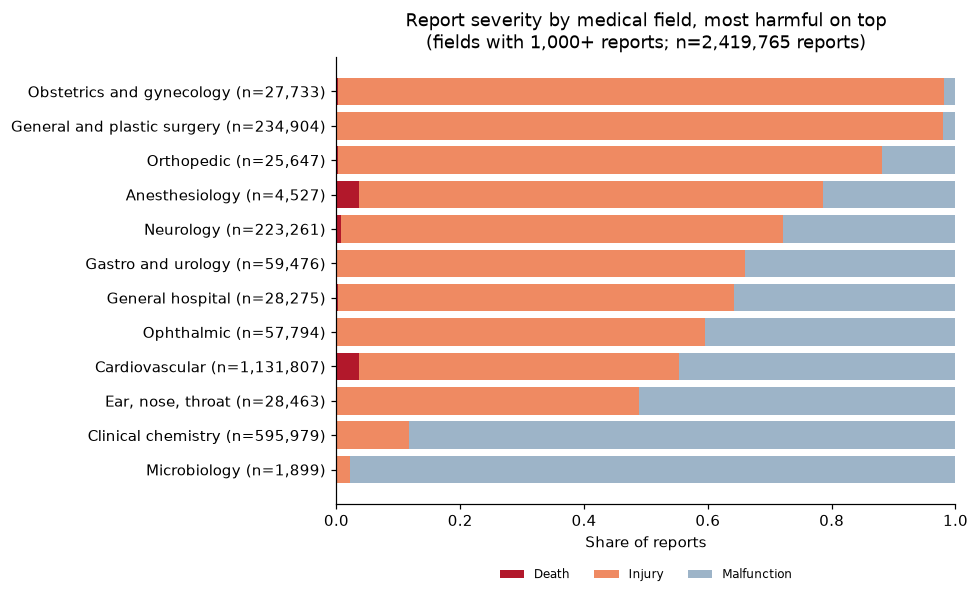

In [36]:
mix = pd.crosstab(reports["committee"], reports["event_type"], normalize="index").reindex(columns=SEVERITY_ORDER)
mix = mix[field.loc[mix.index, "reports"] >= 1_000]
mix = mix.loc[(mix["Death"] + mix["Injury"]).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 0.38 * len(mix) + 1))
left = np.zeros(len(mix))
mix_labels = with_n(mix.index, field.loc[mix.index, "reports"])
for kind in SEVERITY_ORDER:
    ax.barh(mix_labels, mix[kind], left=left, color=SEVERITY_COLORS[kind], label=kind)
    left += mix[kind].values
ax.set(xlim=(0, 1), xlabel="Share of reports",
       title=f"Report severity by medical field, most harmful on top\n(fields with 1,000+ reports; n={field.loc[mix.index, 'reports'].sum():,} reports)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
mix.round(3)

Devices with no death report at all: 57%


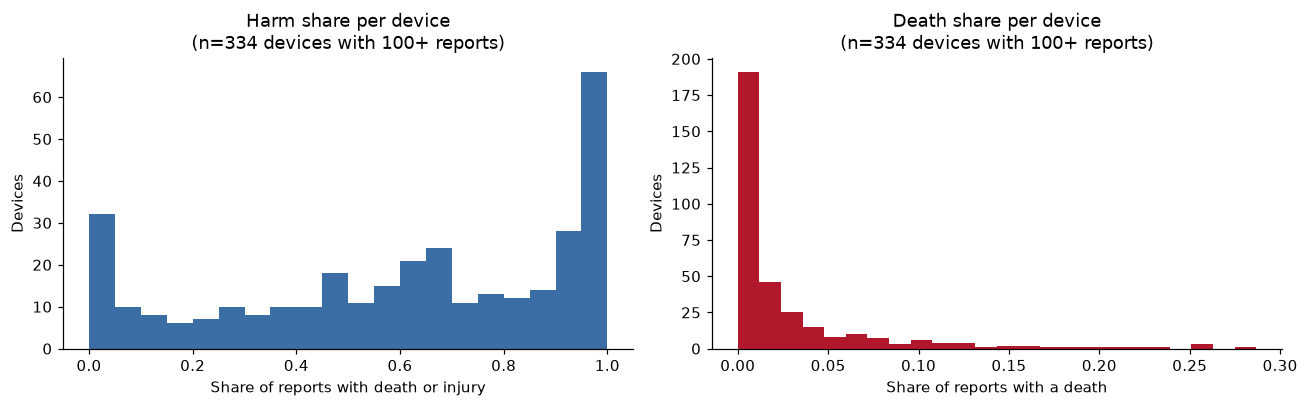

In [37]:
enough = devices[devices["n_reports"] >= 100]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.hist(enough["harm_share"], bins=20, range=(0, 1), color=BLUE)
ax1.set(xlabel="Share of reports with death or injury", ylabel="Devices", title=f"Harm share per device\n(n={len(enough)} devices with 100+ reports)")

ax2.hist(enough["death_share"], bins=np.linspace(0, enough["death_share"].max(), 25), color=SEVERITY_COLORS["Death"])
ax2.set(xlabel="Share of reports with a death", ylabel="Devices", title=f"Death share per device\n(n={len(enough)} devices with 100+ reports)")
plt.tight_layout()
print(f"Devices with no death report at all: {(devices['n_deaths'] == 0).mean():.0%}")

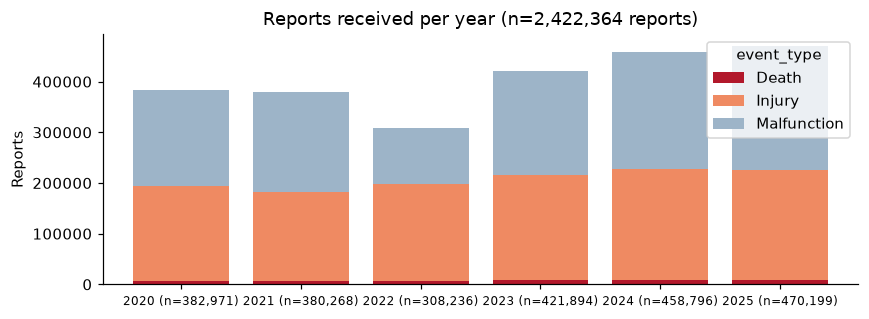

In [38]:
by_year = pd.crosstab(reports["year_received"], reports["event_type"]).reindex(columns=SEVERITY_ORDER)

fig, ax = plt.subplots(figsize=(8, 3))
by_year.plot(kind="bar", stacked=True, color=[SEVERITY_COLORS[k] for k in SEVERITY_ORDER], ax=ax, width=0.8)
ax.set(xlabel="", ylabel="Reports", title=f"Reports received per year (n={by_year.values.sum():,} reports)")
ax.set_xticks(range(len(by_year)), with_n(by_year.index, by_year.sum(axis=1)), rotation=0, fontsize=8)
plt.tight_layout()

## 6. Summary

**What we have**

- **713 devices and 2,422,364 reports**, all linked. Of the 920 devices active in 2020-2025, 207 have no report and are dropped. No report is lost: every report names a device in the table.
- **Each report is one report-device pair.** 4,036 reports (0.2%) list more than one physical device, but they all carry a single PMA number.
- The devices span 249 product codes and 332 manufacturer names (unresolved, so fewer real companies).

**Reports per device are extremely uneven**

- The median device has 75 reports, the largest has 203,612 (MiniMed 670G insulin pump).
- 16 devices hold half of all reports and the top 10 hold 39%. 192 devices have fewer than 10.
- Diabetes devices (insulin pumps, glucose monitors), cardiac leads and breast implants dominate. Any network or text measure has to be checked against this skew, for example with a null model that keeps each device's report count, and a minimum report count per device.

**Patients**

- Sex is known in only 53% of reports. Where known, 53% are female, but this depends on the device: breast implants and gynecology devices are about 100% female, cardiovascular devices 36%.
- A usable age is in 65% of reports. The median is 62 (middle half 46-73). 4,340 ages above 110 were treated as errors.

**Devices**

- Cardiovascular devices are 46% of devices and 47% of reports. Clinical chemistry (mostly glucose monitors) is only 2% of devices but 25% of reports. Microbiology and pathology tests have many devices but almost no reports.
- A quarter of the devices were first approved before 2000, and the median device has 33 supplements.

**Severity, in place of a risk class**

- All devices are class III, so the FDA risk class does not vary. Severity comes from the reports: 1.8% deaths, 49.6% injuries, 48.6% malfunctions without harm.
- Severity is driven by the medical field and by how each field reports. Breast implants and gynecology devices are 98% injury, glucose monitors and lab tests are mostly malfunctions. Deaths concentrate in cardiovascular and anesthesiology devices (3.6% of reports). 57% of devices have no death report.
- Outcomes are missing in 48% of reports.

**Decisions this suggests**

1. Set a minimum number of reports per device before computing shares such as `harm_share` (100 keeps 334 devices).
2. Compare devices within the same medical field, or control for it, because field drives both sex and severity.
3. Treat sex and age as partial: report coverage alongside any result that uses them.